In [ ]:
import pandas as pd

data = {
    "Order ID": ["ORD001", "ORD002", "ORD003", "ORD004", "ORD005",
                 "ORD006", "ORD007", "ORD008", "ORD009", "ORD010"],

    "Order Date": ["2024-01-05", "2024-01-12", "2024-02-03", "2024-02-15",
                   "2024-03-02", "2024-03-18", "2024-04-06", "2024-04-22",
                   "2024-05-10", "2024-05-25"],

    "Customer Name": ["John", "Mary", "Peter", "Sarah", "David",
                      "Grace", "James", "Linda", "Michael", "Anna"],

    "Product": ["Laptop", "Mouse", "Keyboard", "Monitor", "Laptop",
                "Headphones", "Mouse", "Tablet", "Monitor", "Laptop"],

    "Category": ["Computers", "Accessories", "Accessories", "Computers", "Computers",
                 "Audio", "Accessories", "Mobile Devices", "Computers", "Computers"],

    "Region": ["Port Moresby", "Lae", "Madang", "Port Moresby", "Goroka",
               "Lae", "Wewak", "Port Moresby", "Madang", "Lae"],

    "Quantity": [2, 5, 3, 1, 2, 4, 6, 2, 3, 1],

    "Unit Price": [700, 30, 35, 250, 700, 60, 30, 300, 250, 700]
}

df = pd.DataFrame(data)

# Calculate total sales
df["Sales"] = df["Quantity"] * df["Unit Price"]

# Convert Order Date to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Display the dataset
df

,Order ID,Order Date,Customer Name,Product,Category,Region,Quantity,Unit Price,Sales
0,ORD001,2024-01-05,John,Laptop,Computers,Port Moresby,2,700,1400
1,ORD002,2024-01-12,Mary,Mouse,Accessories,Lae,5,30,150
2,ORD003,2024-02-03,Peter,Keyboard,Accessories,Madang,3,35,105
3,ORD004,2024-02-15,Sarah,Monitor,Computers,Port Moresby,1,250,250
4,ORD005,2024-03-02,David,Laptop,Computers,Goroka,2,700,1400
5,ORD006,2024-03-18,Grace,Headphones,Audio,Lae,4,60,240
6,ORD007,2024-04-06,James,Mouse,Accessories,Wewak,6,30,180
7,ORD008,2024-04-22,Linda,Tablet,Mobile Devices,Port Moresby,2,300,600
8,ORD009,2024-05-10,Michael,Monitor,Computers,Madang,3,250,750
9,ORD010,2024-05-25,Anna,Laptop,Computers,Lae,1,700,700


In [ ]:
# Check the structure of the dataset
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Get basic statistics
print("\nSummary statistics:")

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       10 non-null     object        
 1   Order Date     10 non-null     datetime64[ns]
 2   Customer Name  10 non-null     object        
 3   Product        10 non-null     object        
 4   Category       10 non-null     object        
 5   Region         10 non-null     object        
 6   Quantity       10 non-null     int64         
 7   Unit Price     10 non-null     int64         
 8   Sales          10 non-null     int64         
dtypes: datetime64[ns](1), int64(3), object(5)
memory usage: 852.0+ bytes

Missing values:
Order ID         0
Order Date       0
Customer Name    0
Product          0
Category         0
Region           0
Quantity         0
Unit Price       0
Sales            0
dtype: int64

Summary statistics:


,Order Date,Quantity,Unit Price,Sales
count,10,10.00000,10.000000,10.000000
mean,2024-03-12 09:36:00,2.90000,305.500000,577.500000
min,2024-01-05 00:00:00,1.00000,30.000000,105.000000
25%,2024-02-06 00:00:00,2.00000,41.250000,195.000000
50%,2024-03-10 00:00:00,2.50000,250.000000,425.000000
75%,2024-04-18 00:00:00,3.75000,600.000000,737.500000
max,2024-05-25 00:00:00,6.00000,700.000000,1400.000000
std,NaN,1.66333,290.272382,492.551464


In [ ]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Remove duplicate rows if any
df = df.drop_duplicates()

# Make sure dates are in the correct format
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Check the cleaned dataset
print("\nDataset after cleaning:")

print(df.info())

Duplicate rows: 0

Missing values:
Order ID         0
Order Date       0
Customer Name    0
Product          0
Category         0
Region           0
Quantity         0
Unit Price       0
Sales            0
dtype: int64

Dataset after cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       10 non-null     object        
 1   Order Date     10 non-null     datetime64[ns]
 2   Customer Name  10 non-null     object        
 3   Product        10 non-null     object        
 4   Category       10 non-null     object        
 5   Region         10 non-null     object        
 6   Quantity       10 non-null     int64         
 7   Unit Price     10 non-null     int64         
 8   Sales          10 non-null     int64         
dtypes: datetime64[ns](1), int64(3), object(5)
memory usage: 852.0+ bytes
None


In [ ]:
# Sales analysis by product

product_sales = (
    df.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales by Product:")

print(product_sales)

Total Sales by Product:
Product
Laptop        3500
Monitor       1000
Tablet         600
Mouse          330
Headphones     240
Keyboard       105
Name: Sales, dtype: int64


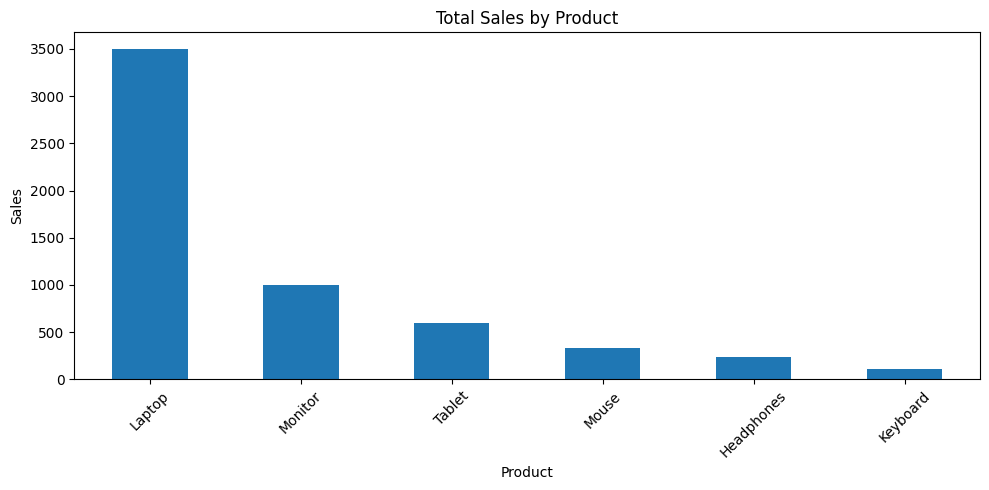

In [ ]:
import matplotlib.pyplot as plt

product_sales.plot(kind="bar", figsize=(10, 5))

plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate percentage contribution to total sales

product_percentage = (product_sales / product_sales.sum() * 100).round(2)

print("Sales Percentage by Product:")

print(product_percentage)

Sales Percentage by Product:
Product
Laptop        60.61
Monitor       17.32
Tablet        10.39
Mouse          5.71
Headphones     4.16
Keyboard       1.82
Name: Sales, dtype: float64


In [ ]:
# Sales analysis by category

category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales by Category:")

print(category_sales)

Total Sales by Category:
Category
Computers         4500
Mobile Devices     600
Accessories        435
Audio              240
Name: Sales, dtype: int64


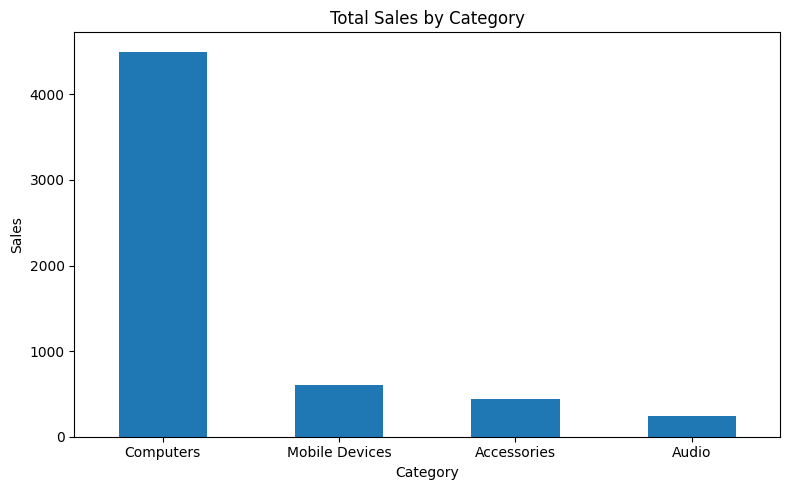

In [ ]:
# Bar chart: Sales by Category

category_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Sales analysis by region

region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales by Region:")

print(region_sales)

Total Sales by Region:
Region
Port Moresby    2250
Goroka          1400
Lae             1090
Madang           855
Wewak            180
Name: Sales, dtype: int64


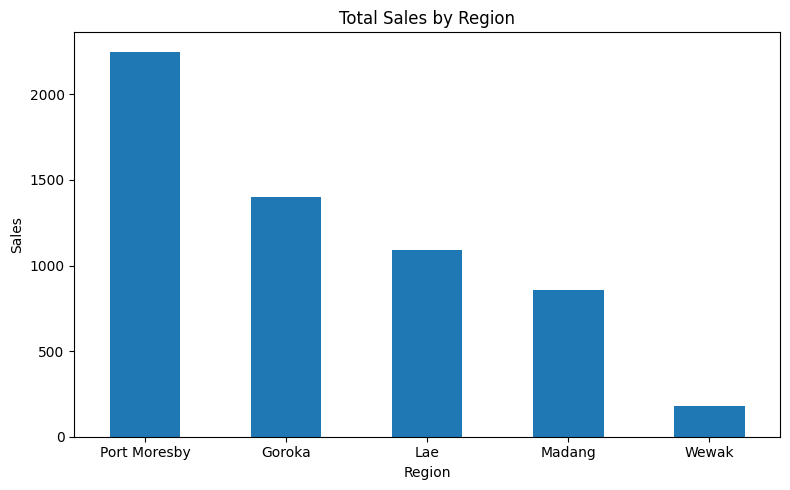

In [ ]:
region_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

print("Monthly Sales:")

print(monthly_sales)

Monthly Sales:
Order Date
2024-01    1550
2024-02     355
2024-03    1640
2024-04     780
2024-05    1450
Name: Sales, dtype: int64


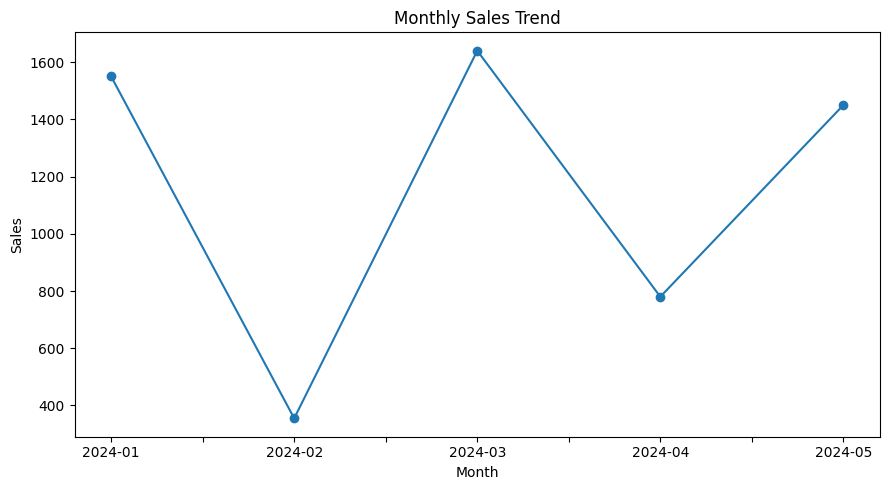

In [ ]:
monthly_sales.plot(kind="line", marker="o", figsize=(9, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
top_product = product_sales.idxmax()
top_product_sales = product_sales.max()

print("Top Performing Product:", top_product)
print("Total Sales:", top_product_sales)

Top Performing Product: Laptop
Total Sales: 3500
